# Лабораторная работа №1 - Анализ и прогнозирование временных рядов на примере розничных продаж

### Выполнил: Жеребцов Сергей
### Группа: М8О-203СВ-25

## 1. Разведочный анализ данных (EDA)

### 1.1. Подготовка

Сначала была загружена таблица и проверено её содержимое - столбцы, типы и пропуски.

In [1]:
# Загрузка всех необходимых библиотек
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

# вывод версий
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__) 

# чтение csv и вывод 5 строк
df = pd.read_csv("retail_sales_mock_data.csv") 
df.head() 

Python: 3.12.3
pandas: 3.0.6


,Date,SalesAmount,Promotion,HolidayMonth
0,2020-01-01,12248,0,0
1,2020-02-01,13011,0,0
2,2020-03-01,12722,0,0
3,2020-04-01,14030,1,0
4,2020-05-01,7783,0,0


In [2]:
print('Размкр таблицы:', df.shape)  # количество строк и столбцов

df.info()  # типы столбцов и число непустых значений

Размкр таблицы: (48, 4)
<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Date          48 non-null     str  
 1   SalesAmount   48 non-null     int64
 2   Promotion     48 non-null     int64
 3   HolidayMonth  48 non-null     int64
dtypes: int64(3), str(1)
memory usage: 1.6 KB


In [3]:
# подготовка таблицы
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")  # приведение к формату год-месяц-день
df = df.set_index("Date").sort_index()  # даты назначены индексом, сортировка по времени
df.head()  # первые 5 строк

,SalesAmount,Promotion,HolidayMonth
Date,,,
2020-01-01,12248,0,0
2020-02-01,13011,0,0
2020-03-01,12722,0,0
2020-04-01,14030,1,0
2020-05-01,7783,0,0


In [4]:
print("начало периода:", df.index.min()) 
print("конец периода:", df.index.max())  
print("повторные даты:", df.index.duplicated().sum())  # сколько дат повторяется
print("Все даты - начало месяца:", df.index.is_month_start.all())  # все ли даты это начало месяца

# календарь месяцев
dates = pd.date_range(  
    start=df.index.min(),  
    end=df.index.max(),  
    freq="MS"
)

missing = dates.difference(df.index)  # месяцы которых нет в таблице

print("отсутствующие месяцы:", missing)  # найденные пропуски календаря

начало периода: 2020-01-01 00:00:00
конец периода: 2023-12-01 00:00:00
повторные даты: 0
Все даты - начало месяца: True
отсутствующие месяцы: DatetimeIndex([], dtype='datetime64[us]', freq='MS')


In [5]:
# Проверки данных
assert df.index.is_unique, "Есть повторные даты"  # без повторов
assert df.index.is_month_start.all(), "не все даты - начало месяца"  # начало месяца
dates = pd.date_range(df.index.min(), df.index.max(), freq="MS")  # полный календарь
assert dates.difference(df.index).empty, "Есть отсутствующие месяцы"  # все месяцы на месте
assert df.notna().all().all(), "в данных есть пропуски"  # без пропусков
assert df["SalesAmount"].gt(0).all(), "Для мультипликативной модели нужны положительные продажи"  # продажи > 0
assert df[["Promotion", "HolidayMonth"]].isin([0, 1]).all().all()  # ттлько 0 и 1

df = df.asfreq("MS")  # месячная частота
df.info()  # типы и пропуски

<class 'pandas.DataFrame'>
DatetimeIndex: 48 entries, 2020-01-01 to 2023-12-01
Freq: MS
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   SalesAmount   48 non-null     int64
 1   Promotion     48 non-null     int64
 2   HolidayMonth  48 non-null     int64
dtypes: int64(3)
memory usage: 1.5 KB


В файле retail_sales_mock_data.csv содержатся 48 месячных наблюдений за январь 2020 - декабрь 2023 года.

Date обозначает месяц наблюдения, SalesAmount - объём продаж. Единицы измерения в исходных данных не указаны. Promotion обозначает наличие акции, HolidayMonth - праздничного месяца: 1 означает наличие признака, 0 - его отсутствие.

В итоге подготовки данных получилось 48 месяцев без пропусков и повторных дат.
Даты были назначены индексом, была задана частота MS, то есть начало месяца.

### 1.2. Обучение и проверка

Для обучения выбраны 2020-2022 годы, всего 36 месяцев.
2023 год остался для проверки. Перемешивать строки здесь нельзя,
иначе прошлое и будущее окажутся вперемешку.

In [6]:
# Разделение на обучающую и тестовую выборки
TEST_SIZE = 12  # размер тестовой выборки в месяцах

train_df = df.iloc[:-TEST_SIZE].copy()  # копирование всего кроме последнего года в обучение
test_df = df.iloc[-TEST_SIZE:].copy()  # копирование последнего года в проверку


print("обучение:", train_df.shape)  # размер обучающей таблицы
print(train_df.index.min(), "-", train_df.index.max())  # начало и конец обучающего периода

print("проверка:", test_df.shape)  # размер проверочной таблицы
print(test_df.index.min(), "-", test_df.index.max())  # начало и конец проверочного периода

обучение: (36, 3)
2020-01-01 00:00:00 - 2022-12-01 00:00:00
проверка: (12, 3)
2023-01-01 00:00:00 - 2023-12-01 00:00:00


### 1.3. График и среднее

Были построены графики продаж за обучающий период и среднего за 12 месяцев.
Среднее сглаживает скачки, но начинается только с двенадцатого значения.

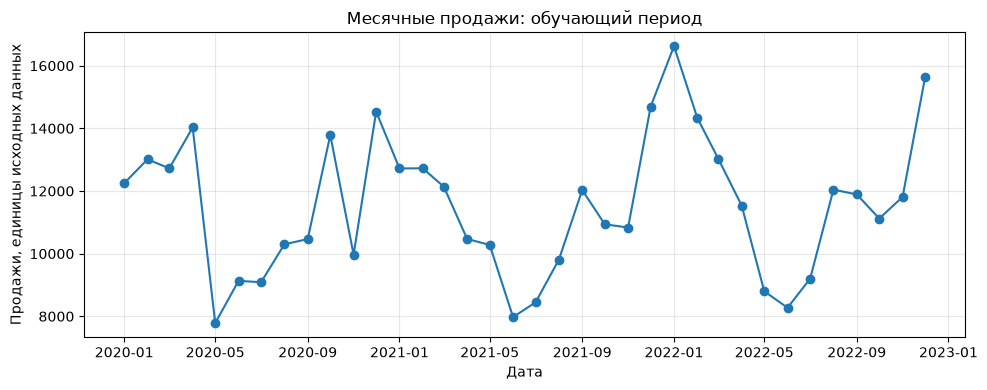

In [7]:
# График месячных продаж за обучающий период
plt.figure(figsize=(10, 4))  

plt.plot(  
    train_df.index,  
    train_df["SalesAmount"],  
    marker="o"  
)

# Легенда
plt.title("Месячные продажи: обучающий период")  
plt.xlabel("Дата") 
plt.ylabel("Продажи, единицы исходных данных")  
plt.grid(True, alpha=0.3)  

plt.tight_layout()  
plt.show()  

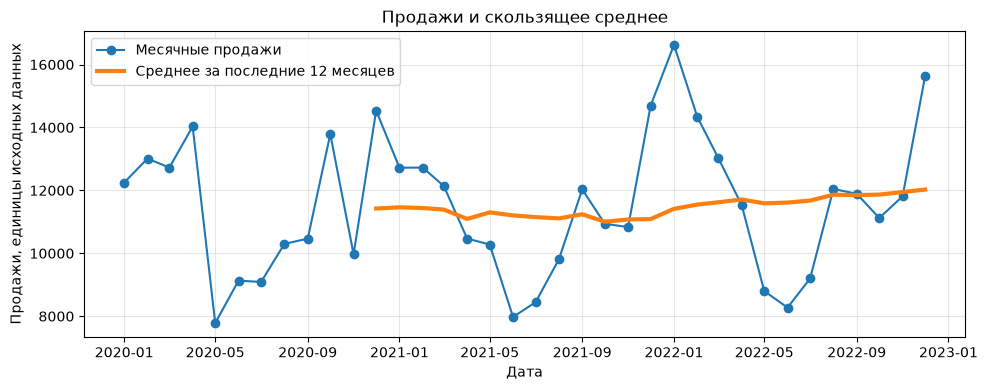

In [8]:
y_train = train_df["SalesAmount"]  # только продажи из обучения

rolling_mean = y_train.rolling(window=12).mean()  # Среднее для каждой точки

plt.figure(figsize=(10, 4))

# График
plt.plot(
    y_train.index, y_train,  
    marker="o", label="Месячные продажи"  
)

plt.plot(  
    rolling_mean.index, rolling_mean,  
    linewidth=3, label="Среднее за последние 12 месяцев" 
)

# Легенда
plt.title("Продажи и скользящее среднее")
plt.xlabel("Дата")  
plt.ylabel("Продажи, единицы исходных данных")  
plt.legend()  
plt.grid(True, alpha=0.3)  
plt.tight_layout()  
plt.show()  

На графике наблюдаются спады примерно в мае и июне и подъёмы ближе к концу и началу года.
Среднее значение держится около 11-12 тысяч, сильного постоянного роста не наблюдается. 

### 1.4. Тепловая карта продаж

Продажи были сгруппированы по месяцам и годам, только за обучение.
Строки это месяцы, а столбцы - годы, число и цвет в клетке показывают продажи.
Зелёный цвет означает меньшие значения а красный большие.
В таблице одна запись на каждый месяц, поэтому усреднение не меняет значение клетки.


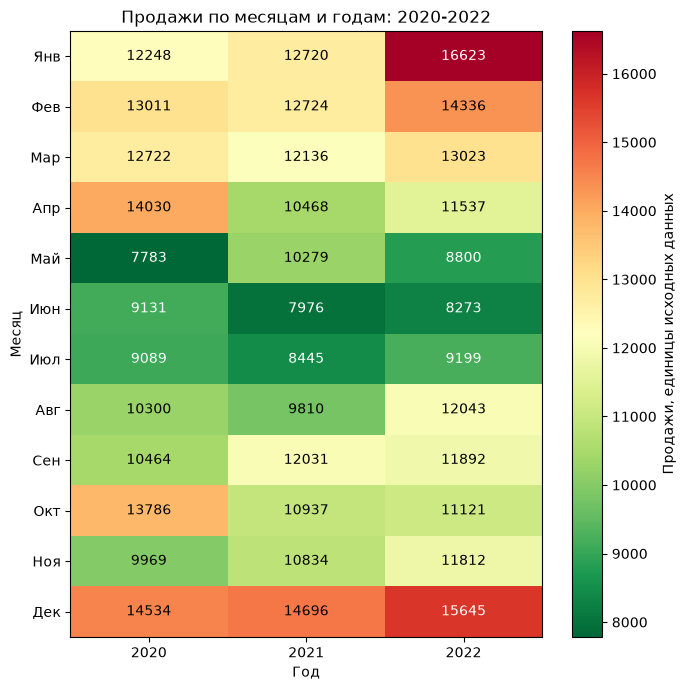

In [9]:
# подготовка месяцев и годов
heat = train_df.copy()
heat["month"] = heat.index.month
heat["year"] = heat.index.year

# Таблица
# строки - месяцы, столбцы - годы, значения - продажи
heat = heat.pivot_table(
    values="SalesAmount",
    index="month",
    columns="year",
    aggfunc="mean"
)

# Подписи месяцев
months = [
    "Янв", "Фев", "Мар", "Апр", "Май", "Июн",
    "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"
]

# Цветная карта
fig, ax = plt.subplots(figsize=(7, 7))
img = ax.imshow(
    heat.to_numpy(),
    cmap="RdYlGn_r",
    aspect="auto"
)

# Оформление осей
ax.set_xticks(np.arange(len(heat.columns)))
ax.set_xticklabels(heat.columns)
ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels(months)

# Числа внутри клеток
for i in range(len(heat.index)):
    for j in range(len(heat.columns)):
        value = heat.iloc[i, j]
        ratio = img.norm(value)

        # Контрастный цвет цифр
        if ratio < 0.2 or ratio > 0.8:
            color = "white"
        else:
            color = "black"

        ax.text(
            j, i, f"{value:.0f}",
            ha="center", va="center",
            color=color
        )

# Легенда
fig.colorbar(img, ax=ax, label="Продажи, единицы исходных данных")
ax.set_title("Продажи по месяцам и годам: 2020-2022")
ax.set_xlabel("Год")
ax.set_ylabel("Месяц")
plt.tight_layout()
plt.show()

В 2020 году минимум пришёлся на май (7783)

в 2021 и 2022 на июнь (7976 и 8273).

Декабрь во всех трёх годах значительно выше летних месяцев.

### 1.5. Разложение


Были применены три способа разложения. В аддитивном разложении сезонность прибавляется к тренду. В мультипликативном она задаётся множителем - коэффициент 1.2 означает продажи на 20% выше тренда. STL позволяет сезонной части меняться со временем, а robust=True уменьшает влияние отдельных необычно высоких или низких значений.

Период 12 был задан вручную, так что эти графики ещё не доказывают, что цикл именно годовой.
У STL seasonal=13 отвечает за сглаживание, а не за период в 13 месяцев.

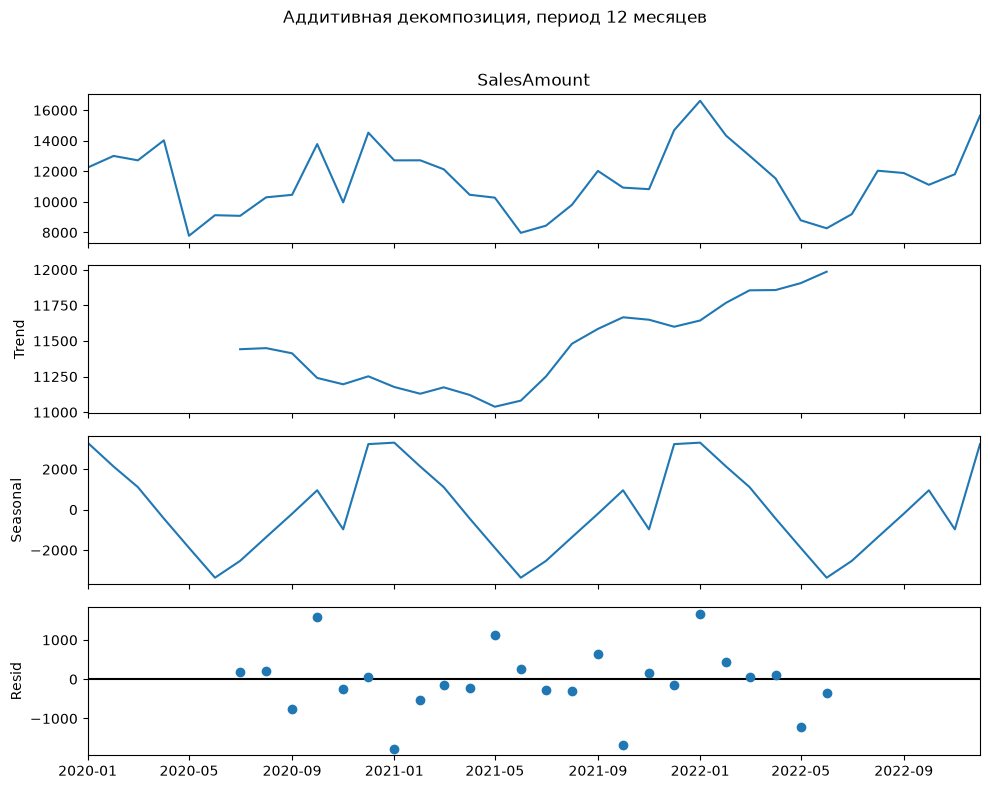

In [10]:
from statsmodels.tsa.seasonal import seasonal_decompose

# аддитивное разложение с годовым периодом
decomp_add = seasonal_decompose(
    y_train,
    model="additive",
    period=12
)

# Графики тренда, сезонности и остатков
fig = decomp_add.plot()
fig.set_size_inches(10, 8)

# Заголовок и размещение графиков
fig.suptitle("Аддитивная декомпозиция, период 12 месяцев")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

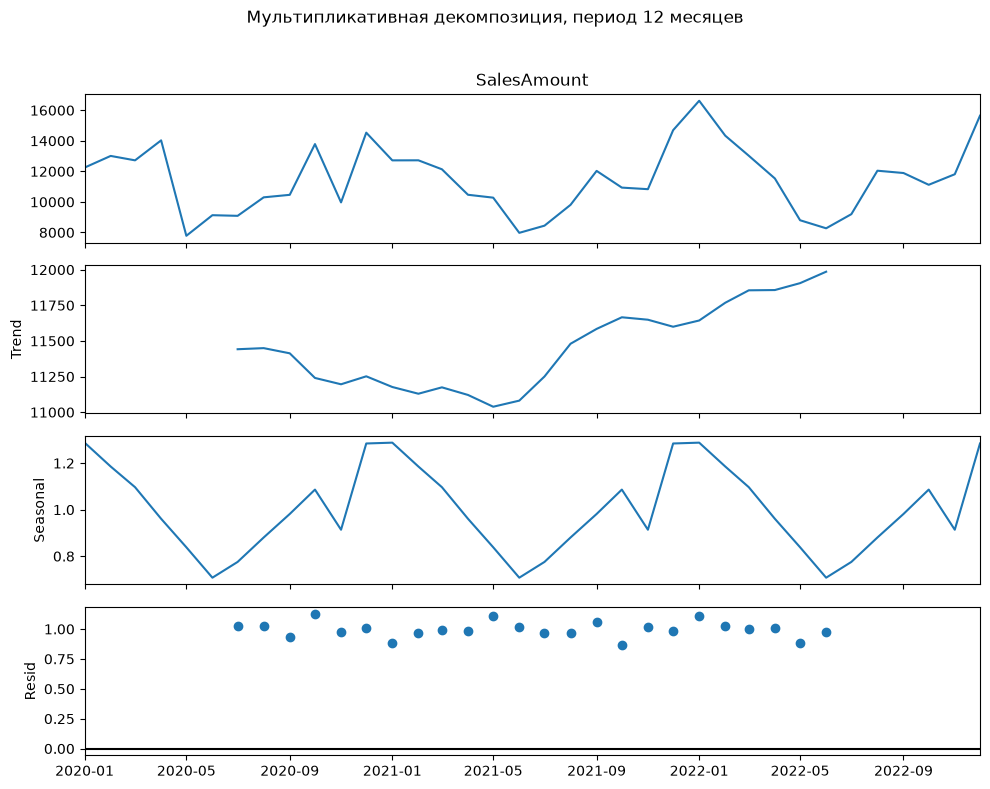

In [11]:
# Мультипликативное разложение с годовым периодом
decomp_mul = seasonal_decompose(
    y_train,
    model="multiplicative",
    period=12
)

# Графики тренда, сезонности и остатков
fig = decomp_mul.plot()
fig.set_size_inches(10, 8)

# Заголовок и размещение графиков
fig.suptitle("Мультипликативная декомпозиция, период 12 месяцев")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

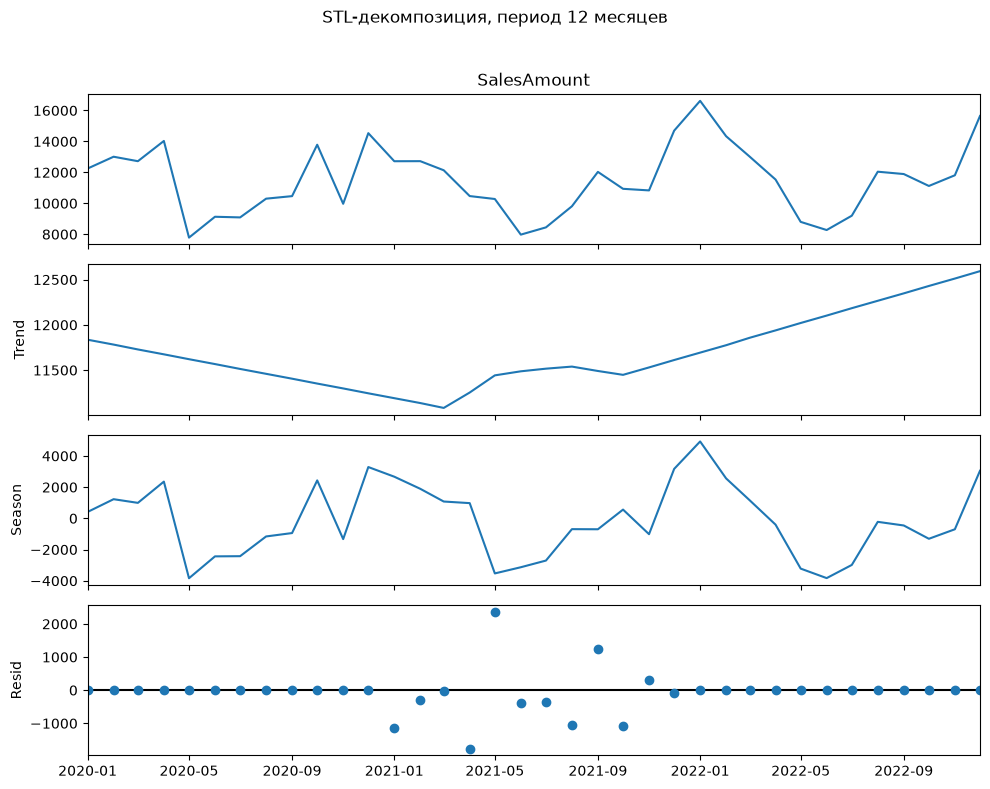

In [12]:
from statsmodels.tsa.seasonal import STL

# годовой период, сглаживание сезонности и снижение влияния выбросов
stl = STL(
    y_train,
    period=12,
    seasonal=13,
    robust=True
)
stl_result = stl.fit()

# Графики тренда, сезонности и остатков
fig = stl_result.plot()
fig.set_size_inches(10, 8)

# Заголовок и размещение графиков
fig.suptitle("STL-декомпозиция, период 12 месяцев")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

В сезонной части заметны более высокие продажи в конце и начале года и более низкие весной-летом.
В аддитивном разложении остатки колеблются около 0. Положительные значения означают продажи выше уровня, объяснённого трендом и сезонностью, отрицательные - ниже. В мультипликативном разложении остатки колеблются около 1, поскольку показывают отношение, а не разницу.
Обычный тренд обрывается по краям, потому что для расчёта не хватает соседних месяцев.
У STL края заполнены, но почти нулевые остатки не означают идеальный результат:
метод мог слишком сильно подстроиться под короткий ряд.


### 1.6. FFT

Для поиска периодов сначала был удалён линейный тренд, потом рассчитано rfft.
Шаг - один месяц, период получается как 1/f. Нулевая частота была пропущена.
Высота пика - модуль коэффициента FFT, не продажи.
Для ARIMA и SARIMAX ниже был оставлен исходный ряд.

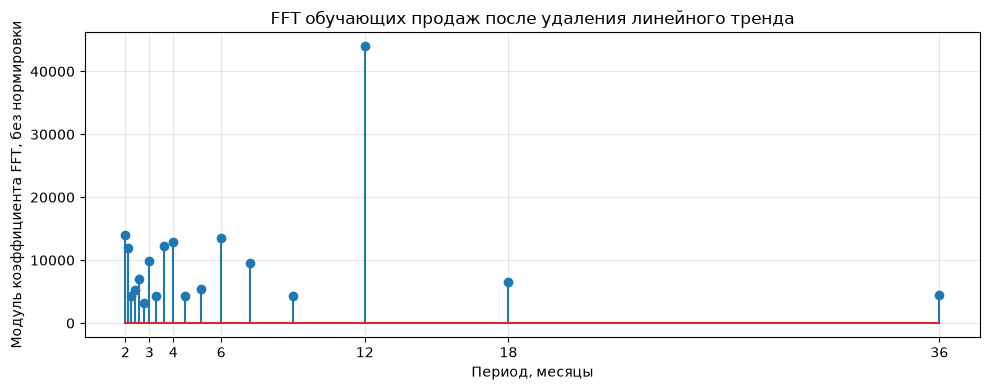

In [13]:
import numpy as np
from scipy.signal import detrend
from scipy.fft import rfft, rfftfreq

# удаление линейного тренда
sales_detrended = detrend(y_train.to_numpy(), type="linear")

# FFT и частоты с шагом в один месяц
n = len(sales_detrended)
fft_values = rfft(sales_detrended)
frequencies = rfftfreq(n, d=1)

# Периоды и модули коэффициентов без нулевой частоты
periods = 1 / frequencies[1:]
magnitudes = np.abs(fft_values[1:])

# График спектра
plt.figure(figsize=(10, 4))
plt.stem(periods, magnitudes)

# Легенда
plt.title("FFT обучающих продаж после удаления линейного тренда")
plt.xlabel("Период, месяцы")
plt.ylabel("Модуль коэффициента FFT, без нормировки")
plt.xticks([2, 3, 4, 6, 12, 18, 36])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Самый большой пик получился у 12 месяцев. Это уже поддерживает годовой цикл,
так как в FFT он заранее не задавался.
Меньшие пики могут быть шумом или частью формы этого же цикла.

### 1.7. Вейвлеты

Был выбран вейвлет Морле. По горизонтали идут месяцы, по вертикали идут периоды,
цвет показывает модуль коэффициента. Пунктиром отмечены 12 месяцев.

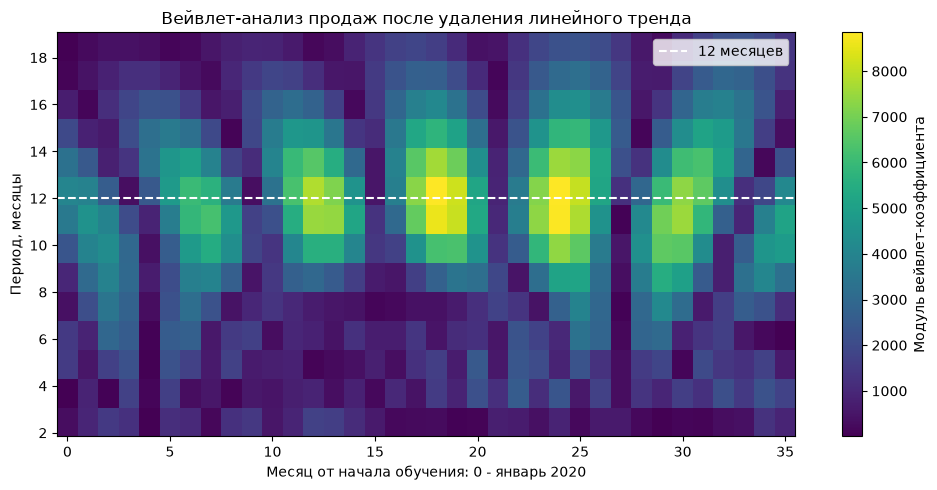

In [14]:
import pywt

# Вейвлет Морле
# масштабы 2-15 и шаг в один месяц
scales = np.arange(2, 16)
coefficients_cwt, frequencies_cwt = pywt.cwt(
    sales_detrended,
    scales,
    "morl",
    sampling_period=1
)

# перевод частот в периоды
periods_cwt = 1 / frequencies_cwt

# цветная карта модулей коэффициентов
plt.figure(figsize=(10, 5))
mesh = plt.pcolormesh(
    np.arange(n),
    periods_cwt,
    np.abs(coefficients_cwt),
    shading="auto",
    cmap="viridis"
)

# цветовая шкала и отметка годового периода
plt.colorbar(mesh, label="Модуль вейвлет-коэффициента")
plt.axhline(12, color="white", linestyle="--", label="12 месяцев")

# Легенда и оформление
plt.title("Вейвлет-анализ продаж после удаления линейного тренда")
plt.xlabel("Месяц от начала обучения: 0 - январь 2020")
plt.ylabel("Период, месяцы")
plt.legend()
plt.tight_layout()
plt.show()

Яркие области в основном около 12 месяцев, что совпадает с FFT.
Но цвет меняется и из-за фазы колебаний, а на краях результат менее надёжен.
По одной картинке нельзя сделать вывод, что сезонность где-то исчезает.

### 1.8. Сравнение способов

| Способ | Что получилось посмотреть | Что мешает |
| --- | --- | --- |
| Обычное разложение | Тренд, сезонность и остаток отдельно | Период задан вручную, на краях нет тренда |
| STL | Более гибкие части ряда | Может сильно подстроиться под короткий ряд |
| FFT | Основные периоды | Не видно, когда именно они проявляются |
| Вейвлеты | Периоды вместе со временем | Края и выбранные настройки влияют на результат |



### Вывод по разделу 1

По графикам обучающей выборки заметно, что продажи меняются в течение года похожим образом: весной летом чаще наблюдается спад, а ближе к концу и началу года - подъём. Также это видно и на тепловой карте. Скользящее среднее держится примерно на уровне 11-12 тысяч, поэтому сильного постоянного роста продаж не наблюдается.

Разложение помогло отдельно рассмотреть общий уровень продаж, сезонные колебания и остатки. В FFT самый большой пик соответствует периоду 12 месяцев, а вейвлет-анализ также показывает заметные колебания около этого периода. Эти результаты поддерживают предположение о годовой сезонности.


## 2. Построение прогнозных моделей - пункт 2.2

### 2.1. ADF

Сначала была проверена необходимость обычных разностей.
ADF проверяет гипотезу о единичном корне - одном из признаков нестационарности.
При p < 0.05 её можно отвергнуть, но тест не проверяет сразу все свойства ряда.

In [15]:
from statsmodels.tsa.stattools import adfuller

# ADF с константой и выбором числа лагов по AIC
adf_result = adfuller(
    y_train,
    regression="c",
    autolag="AIC",
    result_object=False
)

# Результаты теста и критическое значение
print(f"статистика ADF: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")
print(f"количество лагов в тесте: {adf_result[2]}")
print(f"количество использованных наблюдений: {adf_result[3]}")
print(f"критическое значение при 5%: {adf_result[4]['5%']:.4f}")

статистика ADF: -3.7700
p-value: 0.0032
количество лагов в тесте: 5
количество использованных наблюдений: 30
критическое значение при 5%: -2.9641


Получилось p=0.0032, поэтому сначала было выбрано d=0, без обычных разностей.
Для сезонной модели также было выбрано D=0.
ADF отдельно этот сезонный выбор не подтверждает, поэтому далее проверяются остатки.

### 2.2. ACF и PACF

Лаг 1 - прошлый месяц, лаг 12 - тот же месяц год назад.
ACF показывает связь с прошлыми значениями, PACF учитывает промежуточные лаги.
Для короткого ряда были построены графики с 16 лагами.

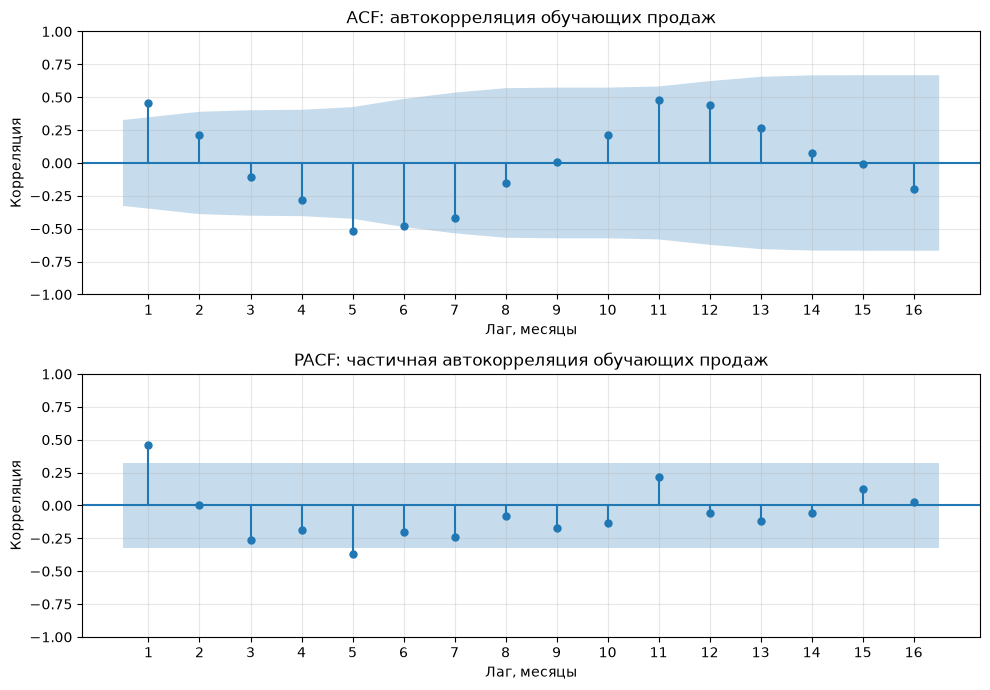

In [16]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Два графика друг под другом
fig, axes = plt.subplots(2, 1, figsize=(10, 7))

# ACF на лагах 1-16, без нулевого лага
plot_acf(
    y_train,
    lags=16,
    ax=axes[0],
    zero=False,
    title="ACF: автокорреляция обучающих продаж"
)

# PACF с расчётом по методу Юла-Уокера
plot_pacf(
    y_train,
    lags=16,
    ax=axes[1],
    zero=False,
    method="ywm",
    title="PACF: частичная автокорреляция обучающих продаж"
)

# Легенда и оформление
for ax in axes:
    ax.set_xlabel("Лаг, месяцы")
    ax.set_ylabel("Корреляция")
    ax.set_xticks(range(1, 17))
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Первый лаг PACF выходит за голубые границы.
На ACF видны колебания, но лаг 12 остаётся внутри границ.
Поэтому решено не выбирать модель только по этим графикам.

### 2.3. ARIMA

В ARIMA(p,d,q): p - лаги ряда, d - порядок разностей, q - лаги ошибок.
Были проверены шесть небольших моделей с d=0 и сравнены AIC/BIC:
в этой таблице меньшие значения лучше.

In [17]:
# Импорт модели ARIMA
from statsmodels.tsa.arima.model import ARIMA

# Набор порядков для сравнения
arima_orders = [
    (0, 0, 0),
    (1, 0, 0),
    (2, 0, 0),
    (0, 0, 1),
    (1, 0, 1),
    (2, 0, 1)
]


models = {}
rows = []

# обучение моделей и сбор AIC, BIC и сходимости
for order in arima_orders:
    fitted = ARIMA(
        y_train,
        order=order,
        trend="c"
    ).fit()

    models[order] = fitted

    rows.append({
        "Порядок": order,
        "AIC": fitted.aic,
        "BIC": fitted.bic,
        "Сходимость": fitted.mle_retvals.get("converged", False)
    })

# таблица с сортировкой по AIC
tbl_arima = (
    pd.DataFrame(rows)
    .sort_values("AIC")
    .reset_index(drop=True)
)


# выбор сошедшейся модели с минимальным AIC
tmp = tbl_arima[tbl_arima["Сходимость"]]
assert not tmp.empty, "Ни одна ARIMA не сошлась"
best_order = tmp.iloc[0]["Порядок"]
model_arima = models[best_order]

# вывод выбранного порядка и таблицы
print("выбранный порядок:", best_order)
tbl_arima.round(2)

выбранный порядок: (1, 0, 0)


/home/sergey/my_project/MAI/predictive-analitics/lab1/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/sergey/my_project/MAI/predictive-analitics/lab1/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,Порядок,AIC,BIC,Сходимость
0,"(1, 0, 0)",653.07,657.82,True
1,"(2, 0, 0)",655.08,661.41,True
2,"(1, 0, 1)",655.15,661.48,True
3,"(0, 0, 1)",655.63,660.38,True
4,"(2, 0, 1)",656.00,663.91,True
5,"(0, 0, 0)",660.35,663.52,True


Из этих шести вариантов лучше вышла ARIMA(1,0,0).
Во время перебора были предупреждения о начальных параметрах,
но итоговая сходимость была проверена в таблице.

### 2.4. SARIMAX

Были добавлены связь через год и признаки акций и праздников.
Был выбран порядок (1,0,0)×(1,0,0,12): небольшие порядки, потому что данных мало.
Период 12 был выбран по графику и FFT

#### Первая попытка

Сначала модель была обучена на продажах без изменения масштаба.

In [18]:
# Импорт модели SARIMAX
from statsmodels.tsa.statespace.sarimax import SARIMAX


# Признаки акций и праздников для обучения
feature_columns = ["Promotion", "HolidayMonth"]
X_train = train_df[feature_columns].astype(float)

# SARIMAX с годовой сезонностью, продажи в исходном масштабе
sarimax_model = SARIMAX(
    y_train,
    exog=X_train,
    order=best_order,
    seasonal_order=(1, 0, 0, 12),
    trend="c"
)

# Обучение модели, максимум 200 итераций
sarimax_result = sarimax_model.fit(
    maxiter=200,
    disp=False
)

# Результаты и проверка сходимости
print(sarimax_result.summary())
print(
    "Сходимость:",
    sarimax_result.mle_retvals.get("converged", False)
)

                                     SARIMAX Results                                      
Dep. Variable:                        SalesAmount   No. Observations:                   36
Model:             SARIMAX(1, 0, 0)x(1, 0, 0, 12)   Log Likelihood                -355.644
Date:                            Thu, 08 Oct 2026   AIC                            723.288
Time:                                    19:06:47   BIC                            732.789
Sample:                                01-01-2020   HQIC                           726.604
                                     - 12-01-2022                                         
Covariance Type:                              opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
intercept     8116.1989   4577.481      1.773      0.076    -855.500    1.71e+04
Promotion     1.277e+04   217

Получилось не сразу. AIC около 723, и есть предупреждение о почти вырожденной
матрице ковариаций. Даже при Сходимость: True оценкам неопределённости коэффициентов доверять нельзя.

#### Повторный запуск

Обучение было повторено: продажи были поделены на 1000, число итераций SARIMAX увеличено.
ARIMA также была обучена на этом масштабе, чтобы сравнить AIC/BIC в одинаковых единицах.

In [19]:
# уменьшение масштаба продаж для устойчивости расчётов
k = 1000.0
y = y_train / k

# обучающие признаки с месячной частотой
X_train = (
    train_df[["Promotion", "HolidayMonth"]]
    .asfreq("MS")
    .astype(float)
)

# обучение ARIMA на уменьшенных продажах
res_arima = ARIMA(
    y,
    order=best_order,
    trend="c"
).fit()

# повторное обучение SARIMAX с увеличенным числом итераций
res_sarimax = SARIMAX(
    y,
    exog=X_train,
    order=best_order,
    seasonal_order=(1, 0, 0, 12),
    trend="c"
).fit(
    maxiter=500,
    disp=False
)

# сводка модели и проверка сходимости
print(res_sarimax.summary())
print(
    "Сходимость:",
    res_sarimax.mle_retvals.get("converged", False)
)

# сравнение AIC и BIC
res_aic = pd.DataFrame([
    {
        "Модель": "ARIMA(1, 0, 0)",
        "AIC": res_arima.aic,
        "BIC": res_arima.bic
    },
    {
        "Модель": "SARIMAX(1, 0, 0)x(1, 0, 0, 12)",
        "AIC": res_sarimax.aic,
        "BIC": res_sarimax.bic
    }
])

res_aic.round(2)

                                     SARIMAX Results                                      
Dep. Variable:                        SalesAmount   No. Observations:                   36
Model:             SARIMAX(1, 0, 0)x(1, 0, 0, 12)   Log Likelihood                 -52.572
Date:                            Thu, 08 Oct 2026   AIC                            117.145
Time:                                    19:06:48   BIC                            126.646
Sample:                                01-01-2020   HQIC                           120.461
                                     - 12-01-2022                                         
Covariance Type:                              opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
intercept        1.1147      0.620      1.799      0.072      -0.100       2.329
Promotion        2.6018      

,Модель,AIC,BIC
0,"ARIMA(1, 0, 0)",155.66,160.41
1,"SARIMAX(1, 0, 0)x(1, 0, 0, 12)",117.14,126.65


После повторного запуска прежнего предупреждения нет.

AIC у SARIMAX около 117, у ARIMA - 156. BIC тоже меньше у SARIMAX.

Акции связаны с ростом продаж, а отдельный эффект праздников оценён неуверенно (p≈0.228).
Это ещё не доказывает, что именно акции вызвали рост.

### 2.5. Прогноз

Был сделан прогноз на весь 2023 год из конца 2022 года, без добавления новых продаж.
Для SARIMAX были использованы будущие акции и праздники с предположением, что их план известен заранее.
Результаты и границы интервала были умножены на 1000 для возврата к исходным единицам.

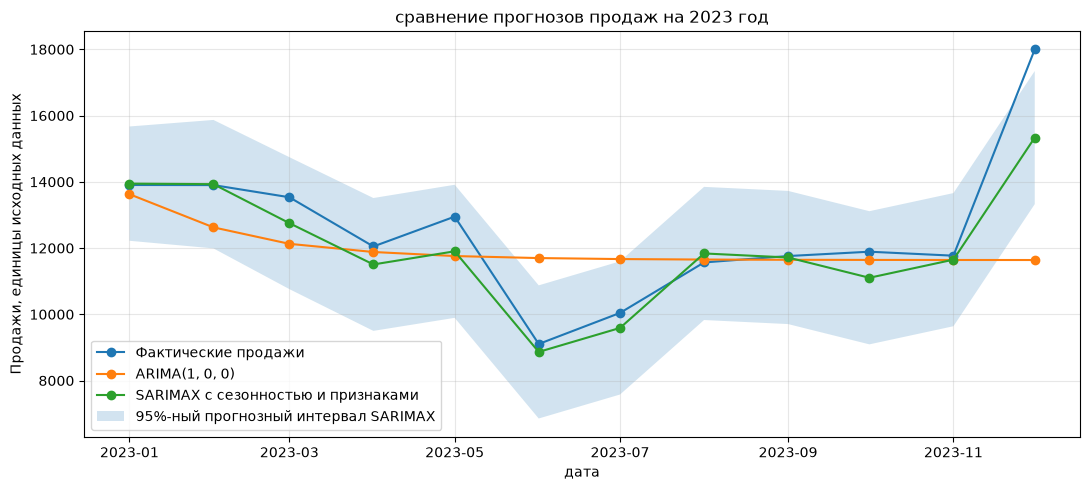

In [20]:
# акции и праздники на проверочный период, без продаж
X_test = (
    test_df[["Promotion", "HolidayMonth"]]
    .asfreq("MS")
    .astype(float)
)

# прогноз SARIMAX с будущими признаками
forecast = res_sarimax.get_forecast(
    steps=len(test_df),
    exog=X_test
)

# прогнозы и 95%-ный интервал в исходных единицах
pred_sarimax = forecast.predicted_mean * k
interval = forecast.conf_int(alpha=0.05) * k
pred_arima = res_arima.forecast(steps=len(test_df)) * k

# фактические продажи и прогнозы обеих моделей
plt.figure(figsize=(11, 5))

plt.plot(
    test_df.index,
    test_df["SalesAmount"],
    marker="o",
    label="Фактические продажи"
)

plt.plot(
    pred_arima.index,
    pred_arima,
    marker="o",
    label="ARIMA(1, 0, 0)"
)

plt.plot(
    pred_sarimax.index,
    pred_sarimax,
    marker="o",
    label="SARIMAX с сезонностью и признаками"
)

# Заливка между нижней и верхней границами интервала
plt.fill_between(
    interval.index,
    interval.iloc[:, 0],
    interval.iloc[:, 1],
    alpha=0.2,
    label="95%-ный прогнозный интервал SARIMAX"
)

# Легенда и оформление
plt.title("сравнение прогнозов продаж на 2023 год")
plt.xlabel("дата")
plt.ylabel("Продажи, единицы исходных данных")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

ARIMA довольно быстро выходит на почти ровную линию.
SARIMAX лучше повторяет спад и подъём, но в декабре всё равно не дотягивает:
около 15.3 тысячи против факта 18 тысяч.
Факт декабря выше верхней границы 95%ного интервала.
Сам интервал не гарантирует попадание каждого месяца.

### Вывод по разделу 2

Были обучены две модели: ARIMA(1,0,0) и SARIMAX(1,0,0)×(1,0,0,12). Порядок ARIMA был выбран по минимальному AIC среди шести проверенных вариантов. В SARIMAX дополнительно были включены годовая сезонность и признаки акций и праздничных месяцев.

При первом обучении SARIMAX появилось предупреждение о ненадёжности оценок коэффициентов. После деления продаж на 1000 и увеличения числа итераций обучение было повторено, и прежнее предупреждение больше не появлялось. Для сравнения AIC и BIC модель ARIMA также была обучена на продажах в этом масштабе. Оба критерия оказались меньше у SARIMAX.

Обе модели дали прогноз на весь 2023 год. Прогноз ARIMA быстро приблизился к постоянному уровню, а SARIMAX лучше повторила спад и последующий подъём продаж. Но декабрьский подъем сезонная модель недооценила. Прогноз SARIMAX предполагает, что план акций и праздников известен заранее.

По графику SARIMAX выглядит точнее, но для окончательного сравнения нужны метрики ошибок и проверка остатков. Они рассмотрены в следующем разделе.

## 3. Оценка качества моделей

### 3.1. Результаты по метрикам

Для проверки качества прогнозы обеих моделей были сравнены с фактическими продажами за 2023 год. Ошибка рассчитана как разница между фактом и прогнозом.

Были рассчитаны MSE, RMSE и R^2. 

Ошибки рассчитаны по 2023 году в исходном масштабе.
AIC и BIC взяты из результатов обучения обеих моделей на продажах, поделённых на 1000.


In [21]:
# сравнение прогнозов и фактических продаж
y_test = test_df["SalesAmount"]

err = pd.DataFrame({
    "ARIMA": y_test - pred_arima,
    "SARIMAX": y_test - pred_sarimax
})

# проверка пропусков после сопоставления по датам
assert err.notna().all().all(), (
    "Проверь совпадение дат фактических продаж и прогнозов"
)

# квадраты ошибок и знаменатель для R^2
err2 = err ** 2
sst = ((y_test - y_test.mean()) ** 2).sum()

# метрики прогноза и критерии моделей в одинаковом масштабе
res = pd.DataFrame({
    "MSE": err2.mean(),
    "RMSE": np.sqrt(err2.mean()),
    "R²": 1 - err2.sum() / sst,
    "AIC": {
        "ARIMA": res_arima.aic,
        "SARIMAX": res_sarimax.aic
    },
    "BIC": {
        "ARIMA": res_arima.bic,
        "SARIMAX": res_sarimax.bic
    }
})

res.round(4)

,MSE,RMSE,R²,AIC,BIC
ARIMA,4.584112e+06,2141.0540,0.0088,155.6596,160.4101
SARIMAX,8.382488e+05,915.5593,0.8188,117.1449,126.6461


У SARIMAX ошибка заметно меньше: MSE около 838249 против 4584112,
RMSE около 916 против 2141. R^2 получился 0.8188 против 0.0088.
Это проверка одного года при заранее известном плане акций и праздников.

### 3.2. Остатки на графиках

Были рассмотрены остатки во времени, их распределение, Q-Q и ACF.
Остатки здесь стандартизованы, поэтому высота линий не сравнивается как ошибка в единицах продаж.

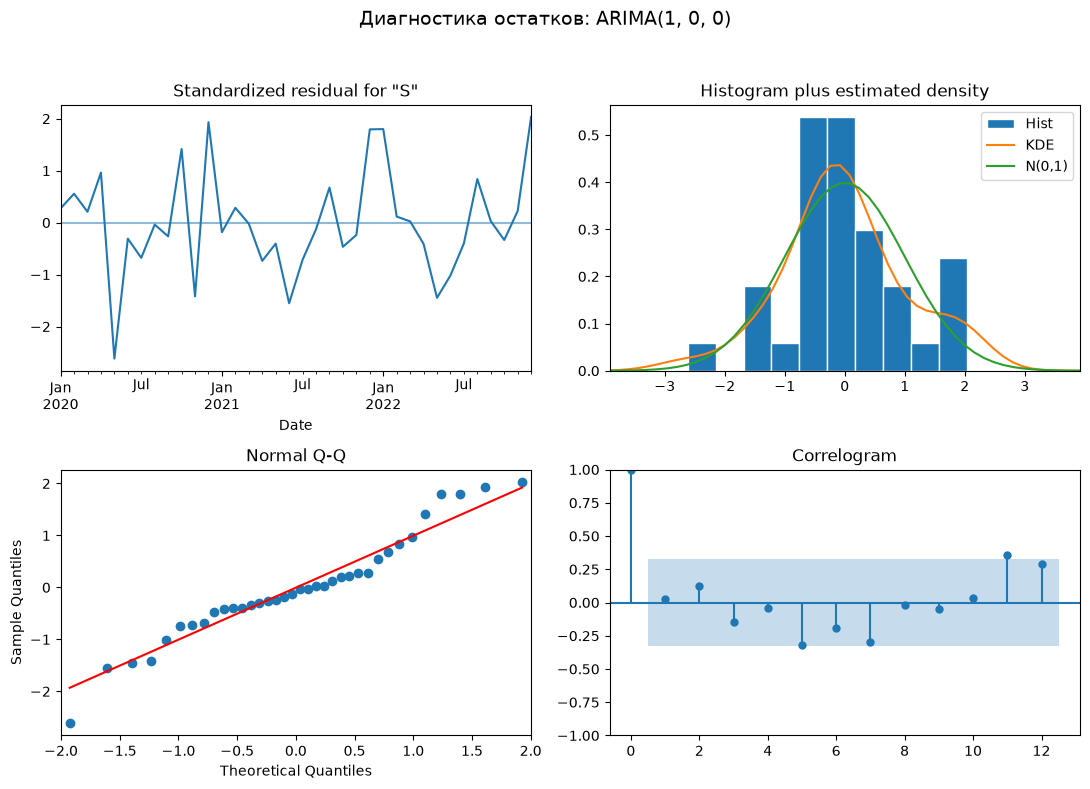

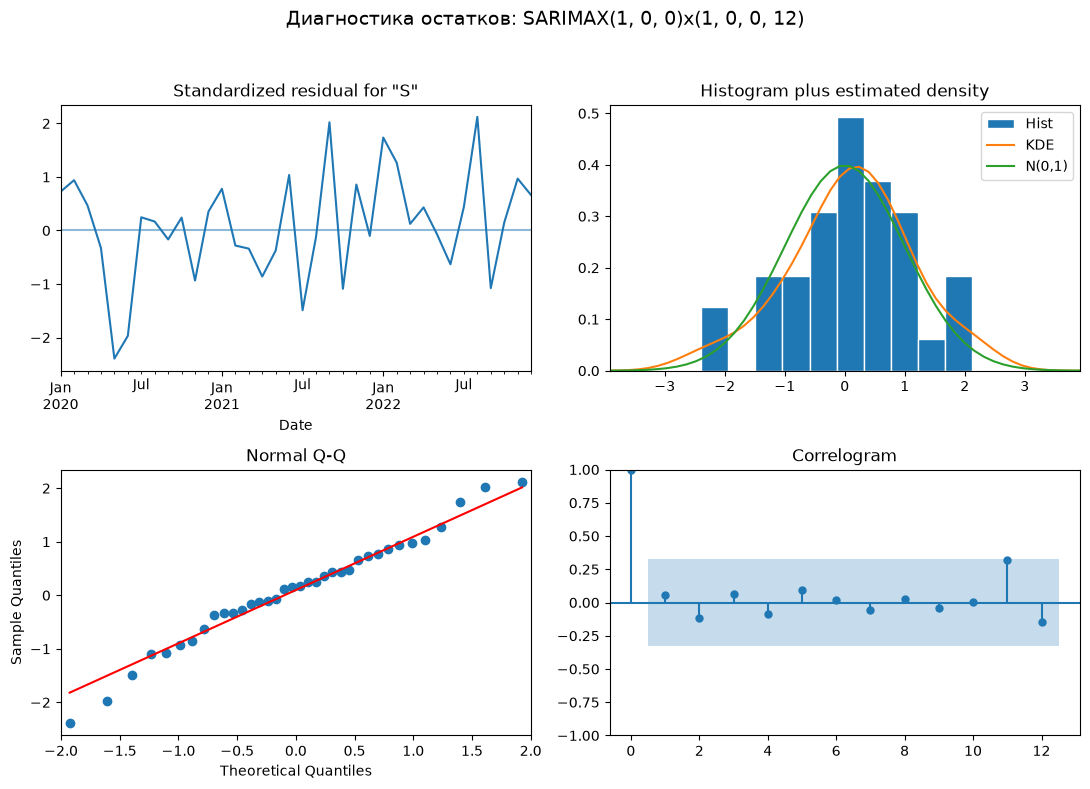

In [22]:
# итоговые модели для диагностики
models_diag = {
    "ARIMA(1, 0, 0)": res_arima,
    "SARIMAX(1, 0, 0)x(1, 0, 0, 12)": res_sarimax
}

# графики остатков и распределения, Q-Q и ACF до лага 12
for name, result in models_diag.items():
    fig = result.plot_diagnostics(
        lags=12,
        figsize=(11, 8)
    )

    # Оформление
    fig.suptitle(f"Диагностика остатков: {name}", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

Остатки в основном около нуля, распределения примерно похожи на нормальные.
У ARIMA связи между остатками заметнее.

### 3.3. Тесты остатков

Льюнг-Бокс проверяет связь на лагах 1-12 с учётом числа AR/MA-параметров,
Ярке-Бера - нормальность, breakvar - постоянство разброса ошибок.
При p < 0.05 есть основание отвергнуть гипотезу теста.
Если p > 0.05, нарушение не обнаружено, но его отсутствие не доказано.

In [23]:
# диагностика моделей

rows_diag = []

for name, result in models_diag.items():
    # fвтокорреляция остатков на лагах 1-12
    ljung_box = result.test_serial_correlation(
        method="ljungbox",
        lags=[12],
        df_adjust=True
    )


    # yормальность остатков
    normality = result.test_normality(
        method="jarquebera"
    )

    # cравнение дисперсии в начале и конце ряда
    variance_test = result.test_heteroskedasticity(
        method="breakvar",
        alternative="two-sided",
        use_f=True
    )

    # p-value тестов для текущей модели
    rows_diag.append({
        "Модель": name,
        "p: Льюнг-Бокс (1-12)": ljung_box[0, 1, 0],
        "p: нормальность": normality[0, 1],
        "p: постоянство дисперсии": variance_test[0, 1]
    })

# таблица результатовв
res_diag = (
    pd.DataFrame(rows_diag)
    .set_index("Модель")
)

res_diag.round(4)

,p: Льюнг-Бокс (1-12),p: нормальность,p: постоянство дисперсии
Модель,,,
"ARIMA(1, 0, 0)",0.0080,0.8940,0.5558
"SARIMAX(1, 0, 0)x(1, 0, 0, 12)",0.2738,0.7922,0.9967


Льюнг-Бокс нашёл зависимость остатков ARIMA (p=0.0080), но не SARIMAX (p=0.2738).
По нормальности и изменению дисперсии у обеих моделей p > 0.05.
Явных проблем по этим двум тестам нет.

### 3.4. Горизонты

Была сравнена RMSE за первые 1, 3, 6 и 12 месяцев одного прогноза.
Например, 6 месяцев - январь-июнь, а не только июнь.
Модели по новым продажам не дообучались.

In [24]:
rows_h = []

# cравнение по месяцам прогнозов и фактических продаж для разных горизонтов
for horizon in [1, 3, 6, 12]:
    actual = y_test.iloc[:horizon]

    # Ошибки моделей за выбранный период
    e1 = actual - pred_arima.iloc[:horizon]
    e2 = actual - pred_sarimax.iloc[:horizon]

    # RMSE по всем месяцам периода
    rows_h.append({
        "Горизонт, месяцев": horizon,
        "RMSE ARIMA": np.sqrt((e1 ** 2).mean()),
        "RMSE SARIMAX": np.sqrt((e2 ** 2).mean())
    })

# таблица ошибок для разных горизонтов
res_h = (
    pd.DataFrame(rows_h)
    .set_index("Горизонт, месяцев")
)

res_h.round(2)

,RMSE ARIMA,RMSE SARIMAX
"Горизонт, месяцев",,
1,277.50,41.14
3,1108.00,452.15
6,1405.73,586.12
12,2141.05,915.56


SARIMAX лучше на всех четырёх горизонтах.
Самый длинный проверенный прогноз - 12 месяцев, RMSE около 916.
Дальше в файле нет факта. Порог допустимой ошибки в задании не указан,
поэтому этот горизонт не считается подходящим для любых условий.

### Вывод по разделу 3

На проверочных данных за 2023 год SARIMAX дала меньшую ошибку: RMSE составила около 916 а ARIMA - 2141, а MSE - около 838 тысяч против 4.58 миллиона. R^2 у SARIMAX получился 0.8188, у ARIMA - 0.0088. AIC и BIC, рассчитанные при обучении в одинаковом масштабе, также оказались ниже у SARIMAX.

Тест Льюнга-Бокса обнаружил зависимость между остатками ARIMA. Это означает, что модель не учла часть связей в ряде. У SARIMAX такая зависимость не была выявлена. Тесты нормальности и постоянства дисперсии не показали явных нарушений у обеих моделей, но для уверенных выводов 36 обучающих наблюдений мало.

SARIMAX показала меньшую RMSE на всех проверенных горизонтах: 1, 3, 6 и 12 месяцев. Поэтому из двух моделей для рассматриваемых данных была выбрана SARIMAX. При этом декабрьский пик продаж остался недооценённым, а результат проверен только на одном году и при предположении, что будущие акции и праздники известны заранее.

## 4. Вывод

В работе были рассмотрены месячные розничные продажи и построены прогнозы на 2023 год. Графики, разложение, FFT и вейвлет-анализ показали признаки годовой сезонности: продажи чаще снижались весной-летом и росли ближе к концу и началу года.

Для прогноза были обучены ARIMA и SARIMAX. На проверочном периоде SARIMAX с сезонностью и признаками акций и праздников показала меньшую ошибку: RMSE составила около 916 против 2141 у ARIMA. Проверка остатков также оказалась в пользу SARIMAX, поэтому из двух вариантов была выбрана эта модель.

При этом прогноз получился не полностью точным: декабрьский пик продаж был недооценён. Результат проверен только на одном году и при предположении, что план акций и праздников известен заранее. Поэтому SARIMAX лучше подошла для рассматриваемых данных, но такая же точность в следующие годы не гарантируется.